**Why Business Leaders Don't Buy 'Black Boxes'**

- The Accuracy of your model does not impress stakeholders

- A 95% model accuracy is worthkess to a business stakeholder if they cannot understand why it makes such decisions.

 **why is it worthless to them**
 - They don't trust it, it lacks clarity, it lack actionable business insights

 - Data visualization acts as the translation layer across the entire ML pipeline

**Business-Valued ML visualization**
- phase 1: Risk and data Quality: There is a business problem of corrupted, heavily bskewed, and incomplete data.

- solution: visualize the errors, extreme outliers, missing information...

- phase 2: ROI(return on investment) and Lever Discoveries: There is a business problem of invesing in factors that won't impact their goals and referred outcomes

- Solution: Visualizing how spending directly impacts their Return on Investment

- phase 3: Model auditing & Trust: Business problem is Knowing the cost of the model's mistakes.

- solution: Visualizing model errors in simple business terms

**Real-World Scenario: You are advising the state Department of Education. They need to allocate $50 Million Intervention fund to improve students performance (Math proficiency)**



**Step 1: Setup Environment & Data ingestion**

In [17]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**step 1

In [18]:
# step 1: stepup Environment & Data ingestion
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# clean & professional visual Aesthetics
sns.set_theme(style='whitegrid', palette='muted')



In [19]:
import os
if os.path.exists('us_education_system_dataset.csv'):
    path = 'us_education_system_dataset.csv'
else:
    path = '/content/drive/MyDrive/second semester project/us_education_system_dataset.csv'


In [20]:
us_edu_data = pd.read_csv(path)


In [21]:
allocation_data= us_edu_data[['institution_name', 'level', 'control', 'title_i_status',
             'per_pupil_expenditure_usd','percent_free_reduced_lunch', 'math_proficiency_pct']]

**step 2: Resource Allocation Audit**
- Business Insight: Leadership must understand how funds are currently distributed accross institutions.

- Are funds evenly spread or concentrated in specific school types?

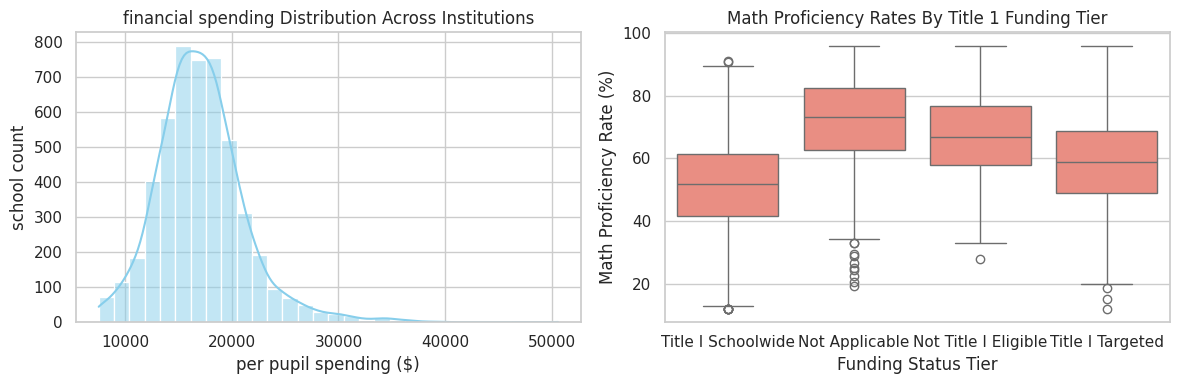

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# plot 1: show financial distribution skewness
sns.histplot(allocation_data['per_pupil_expenditure_usd'],
             kde= True, ax= axes[0], color = 'skyblue', bins=30)
axes[0].set_title('financial spending Distribution Across Institutions')
axes[0].set_xlabel('per pupil spending ($)')
axes[0].set_ylabel('school count')

# plot 2: performance Across Funding Eligiblity
sns.boxplot(data=allocation_data, x='title_i_status', y='math_proficiency_pct',
            ax=axes[1], color = 'salmon')
axes[1].set_title('Math Proficiency Rates By Title 1 Funding Tier')
axes[1].set_xlabel('Funding Status Tier')
axes[1].set_ylabel('Math Proficiency Rate (%)')
plt.tight_layout()
plt.show()
#

**Step 3: Discovering Business levers**

- socioeconomic Needs Vs. Academic Returns

- *Business Insight: "Does Throwing money at schools Solve performance gaps, or are socioeconomic factors stronger drivers?"*

create a multilayered visual mapping socioeconomic needs, funding levels, school types, and math outcomes


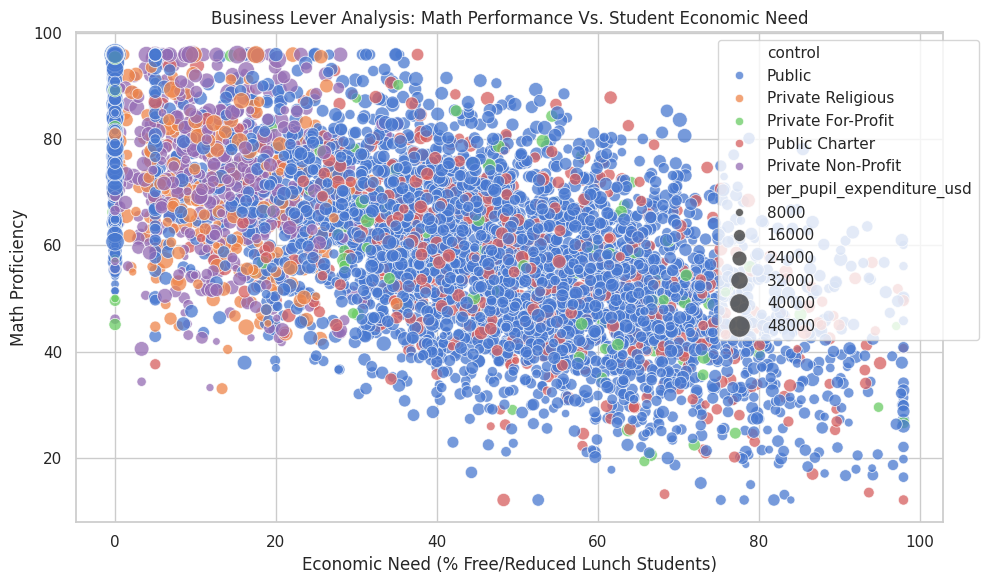

In [23]:
#contol: institutional gorvernance structure and funding mechanism

plt.figure(figsize=(10, 6))
sns.scatterplot(data=allocation_data, x='percent_free_reduced_lunch',
                y='math_proficiency_pct',
                hue='control',
                size= 'per_pupil_expenditure_usd',
                sizes=(30, 250),
                alpha=0.75)

plt.title('Business Lever Analysis: Math Performance Vs. Student Economic Need')
plt.xlabel('Economic Need (% Free/Reduced Lunch Students)')
plt.ylabel('Math Proficiency')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper right' )
plt.tight_layout()
plt.show()

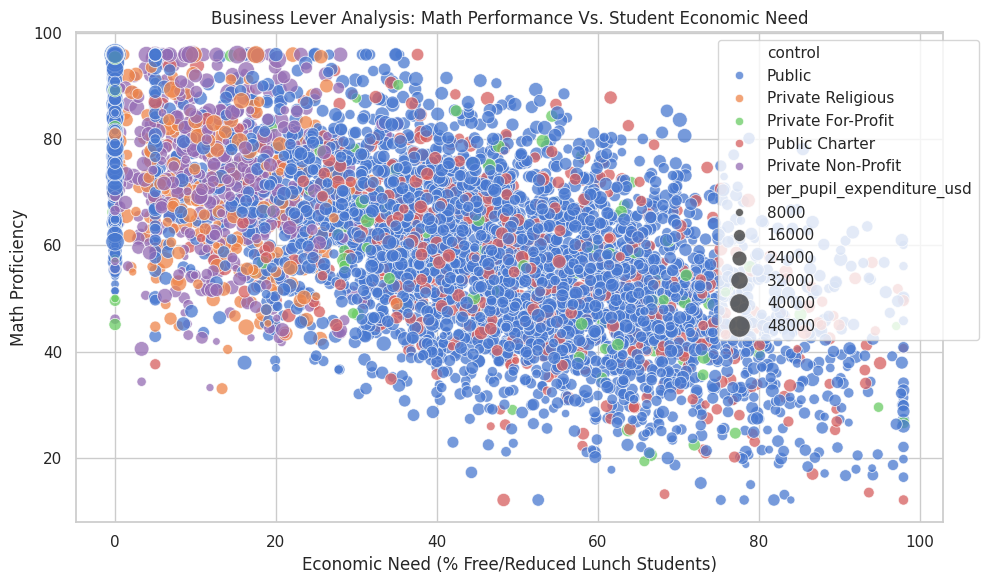

In [24]:
# Title status: Federal Title I'eligibility under ESEA for schools with high concentrations of low-income students.

plt.figure(figsize=(10, 6))
sns.scatterplot(data=allocation_data, x='percent_free_reduced_lunch',
                y='math_proficiency_pct',
                hue='control',
                size= 'per_pupil_expenditure_usd',
                sizes=(30, 250),
                alpha=0.75)

plt.title('Business Lever Analysis: Math Performance Vs. Student Economic Need')
plt.xlabel('Economic Need (% Free/Reduced Lunch Students)')
plt.ylabel('Math Proficiency')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper right' )
plt.tight_layout()
plt.show()

**Step 4: Eliminating Redundant Features

*Business insight:

In [25]:
us_edu_data.columns

Index(['institution_id', 'institution_name', 'state_code', 'state_name',
       'county', 'nces_locale', 'level', 'control', 'title_i_status',
       'total_enrollment', 'number_of_teachers', 'student_teacher_ratio',
       'percent_free_reduced_lunch', 'racial_white_pct', 'racial_black_pct',
       'racial_hispanic_pct', 'racial_asian_pct', 'racial_native_pct',
       'racial_two_or_more_pct', 'special_education_pct',
       'english_learner_pct', 'per_pupil_expenditure_usd',
       'federal_funding_pct', 'state_funding_pct', 'local_funding_pct',
       'math_proficiency_pct', 'reading_proficiency_pct',
       'graduation_rate_pct', 'chronic_absenteeism_pct', 'avg_sat_score',
       'avg_act_score', 'ap_ib_participation_pct',
       'postsecondary_enrollment_pct', 'stem_certified_flag',
       'broadband_access_pct'],
      dtype='object')

In [26]:
# key indicators
key_indicators =['per_pupil_expenditure_usd','student_teacher_ratio','percent_free_reduced_lunch',
 'special_education_pct','english_learner_pct','math_proficiency_pct',
 'reading_proficiency_pct','graduation_rate_pct','broadband_access_pct']

In [27]:
key_indicators

['per_pupil_expenditure_usd',
 'student_teacher_ratio',
 'percent_free_reduced_lunch',
 'special_education_pct',
 'english_learner_pct',
 'math_proficiency_pct',
 'reading_proficiency_pct',
 'graduation_rate_pct',
 'broadband_access_pct']

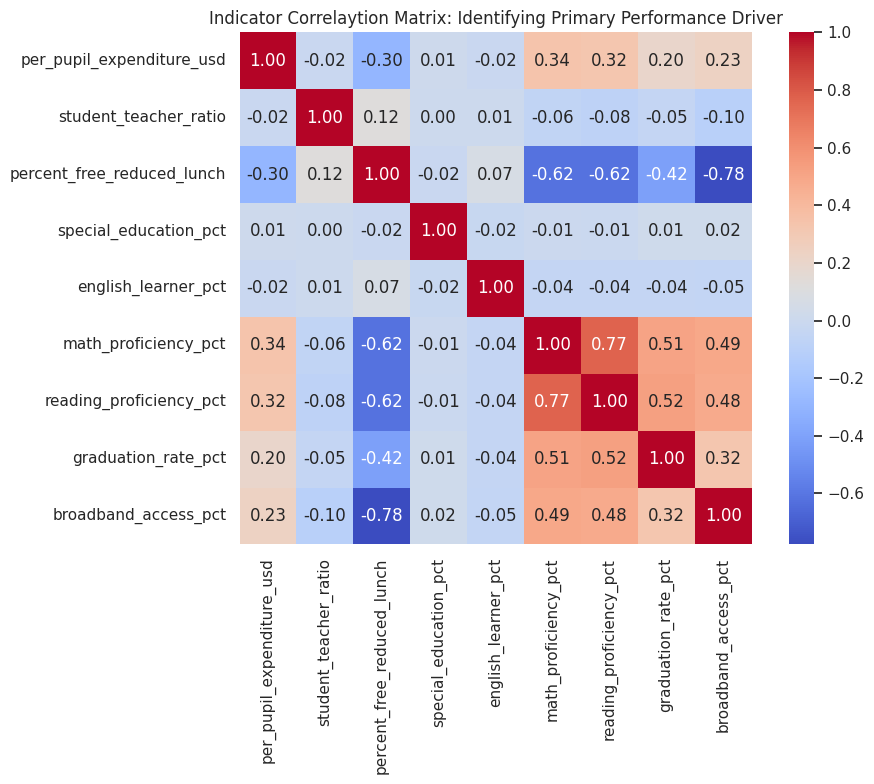

In [28]:
# correlation Heatmap - check correlation coefficients(-1 to +1)
plt.figure(figsize=(10, 8))

# calculate our correlation matrix
corr = us_edu_data[key_indicators].corr()


#clean visual heatmap
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm',
            square=True, cbar= True)
plt.title('Indicator Correlaytion Matrix: Identifying Primary Performance Driver')
plt.tight_layout()
plt.show()